# Ciblage humanitaire avec ML — version 5 : reproduire la décision de l'agent et sélectionner sous budget

Les données (`data/ciblage_v5.db`) reproduisent le processus d'une ONG : la grille de points est validée localement, l'enquête est faite sous Kobo, puis un agent décide dans Excel (voir `generation_donnees_ciblage_v5.ipynb`).

**Rôle du Machine Learning dans ce projet**
1. **Décider** : reproduire la décision de l'agent (éligible ou non) avec **au moins 98 % de précision**, directement à la réception de la soumission Kobo.
2. **Prioriser** : quand le budget ne couvre pas tous les éligibles (par exemple 10 000 éligibles pour 3 000 places), classer les ménages **comme l'agent l'aurait fait**.
3. **Expliquer** chaque décision, pour que le superviseur du backend puisse la confirmer ou la désapprouver.

> Si la grille est entièrement formalisée, une formule la reproduit exactement. Le ML apporte de la valeur quand la décision réelle contient du jugement de l'agent, quand la grille évolue, et pour expliquer, contrôler et prioriser à grande échelle. Ici, la décision est sans bruit : les scores obtenus sont un plafond.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import sqlite3, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.model_selection import train_test_split, cross_val_predict, KFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (precision_score, recall_score, f1_score, accuracy_score, confusion_matrix,
                             ConfusionMatrixDisplay, mean_absolute_error)
from lightgbm import LGBMClassifier, LGBMRegressor
import generateur_ciblage_v5 as gen

sys.path.insert(0, str(Path("..").resolve()))
from app.services import repartir  # la même répartition par zone que le backend

plt.rcParams["figure.dpi"] = 110
SEED = 42

## 1. Les données de l'agent

In [2]:
with sqlite3.connect("data/ciblage_v5.db") as con:
    df = pd.read_sql("SELECT * FROM menages", con)
    grille = pd.read_sql("SELECT * FROM grille", con)
print(f"{len(df):,} ménages — éligibles : {df.eligible.mean():.1%}")
df.motif_decision.value_counts().to_frame("ménages")

100,000 ménages — éligibles : 27.0%


,ménages
motif_decision,
score < 40,54344
score >= 40,23640
exclusion : assistance récente (vivres/cash),11126
exclusion : salaire régulier,7484
inclusion automatique,3406


## 2. Préparation

- **Exclues des variables** : `score_excel` et `motif_decision`, qui sont des *sorties* de la feuille Excel, au même titre que `eligible` (les utiliser serait une fuite), ainsi que `id_menage`, `date_enquete` et `enqueteur`.
- Le **score Excel historique** sert en revanche de **cible secondaire** : un modèle apprend à le prédire (section 4). C'est la clé de la priorisation.
- Les cellules vides signifient « question non posée » (logique de saut Kobo).

In [3]:
SORTIES_EXCEL = ["score_excel", "motif_decision", "eligible"]
X = df.drop(columns=["id_menage", "date_enquete", "enqueteur"] + SORTIES_EXCEL)
y, score = df["eligible"].to_numpy(), df["score_excel"].to_numpy()
CAT = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]
NUM = [c for c in X.columns if c not in CAT]

def preprocesseur(num=NUM):
    return ColumnTransformer([
        ("cat", Pipeline([("vide", SimpleImputer(strategy="constant", fill_value="non_applicable")),
                          ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), CAT),
        ("num", SimpleImputer(strategy="constant", fill_value=0, add_indicator=True), num)])

idx = np.arange(len(df))
i_tr, i_tmp = train_test_split(idx, test_size=0.30, stratify=y, random_state=SEED)
i_va, i_te = train_test_split(i_tmp, test_size=0.50, stratify=y[i_tmp], random_state=SEED)
print(f"{X.shape[1]} variables | train {len(i_tr):,} / validation {len(i_va):,} / test {len(i_te):,}")

26 variables | train 70,000 / validation 15,000 / test 15,000


## 3. Reproduire la décision : trois approches

- **Régression logistique** : le modèle du backend actuel.
- **LightGBM** : arbres de décision boostés.
- **Score prédit + LightGBM (stacking)** : un premier modèle apprend à prédire le *score Excel*. Ce score prédit est ensuite ajouté comme variable au classifieur.
  Pour éviter la fuite, le score prédit du train est calculé **hors-pli** (validation croisée à 5 plis).

In [4]:
def regresseur_score():
    return Pipeline([("pre", preprocesseur()), ("m", LGBMRegressor(n_estimators=1500, learning_rate=0.05, num_leaves=63,
                                                                    random_state=SEED, verbose=-1))])

def classifieur(num=NUM):
    return Pipeline([("pre", preprocesseur(num)), ("m", LGBMClassifier(n_estimators=1500, learning_rate=0.05, num_leaves=63,
                                                                       random_state=SEED, verbose=-1))])

X_tr, X_va, X_te = X.iloc[i_tr], X.iloc[i_va], X.iloc[i_te]

lr = Pipeline([("pre", preprocesseur()), ("sc", StandardScaler()), ("m", LogisticRegression(max_iter=5000))]).fit(X_tr, y[i_tr])
lgbm = classifieur().fit(X_tr, y[i_tr])

modele_score = regresseur_score().fit(X_tr, score[i_tr])
score_oof = cross_val_predict(regresseur_score(), X_tr, score[i_tr], cv=KFold(5, shuffle=True, random_state=SEED))
avec_score = lambda Xp, s: Xp.assign(score_predit=s)
stack = classifieur(NUM + ["score_predit"]).fit(avec_score(X_tr, score_oof), y[i_tr])

def proba_stack(Xp):
    return stack.predict_proba(avec_score(Xp, modele_score.predict(Xp)))[:, 1]

p_va = {"Régression logistique": lr.predict_proba(X_va)[:, 1], "LightGBM": lgbm.predict_proba(X_va)[:, 1],
        "Score prédit + LightGBM": proba_stack(X_va)}
pd.DataFrame({nom: {"précision": precision_score(y[i_va], p >= .5), "rappel": recall_score(y[i_va], p >= .5),
                    "F1": f1_score(y[i_va], p >= .5)} for nom, p in p_va.items()}).T.style.format("{:.4f}").highlight_max(color="#e0f1e6")

,précision,rappel,F1
Régression logistique,0.9179,0.8817,0.8994
LightGBM,0.9831,0.9606,0.9717
Score prédit + LightGBM,0.9943,0.9911,0.9927


- **La régression logistique** ne peut pas représenter les **exclusions** (« salaire régulier », « déjà assisté ») ni les **inclusions automatiques** : ce sont des règles qui *écrasent* le score.
- **LightGBM** les apprend, mais additionner une quinzaine de critères puis comparer le total à 40 est difficile pour des arbres. Les erreurs se concentrent près du seuil.
- **Le stacking** sépare les deux difficultés. Le premier modèle apprend « combien de points » (erreur moyenne d'environ 0,3 point). Le classifieur apprend ensuite « au-dessus du seuil, sauf exclusion ou inclusion automatique ».

## 4. Seuil de décision et résultat sur le test

Seuil retenu sur la validation : 0.37


,précision,rappel,F1,accuracy,erreur moyenne du score prédit (points)
TEST,0.9914,0.9896,0.9905,0.9949,0.3359


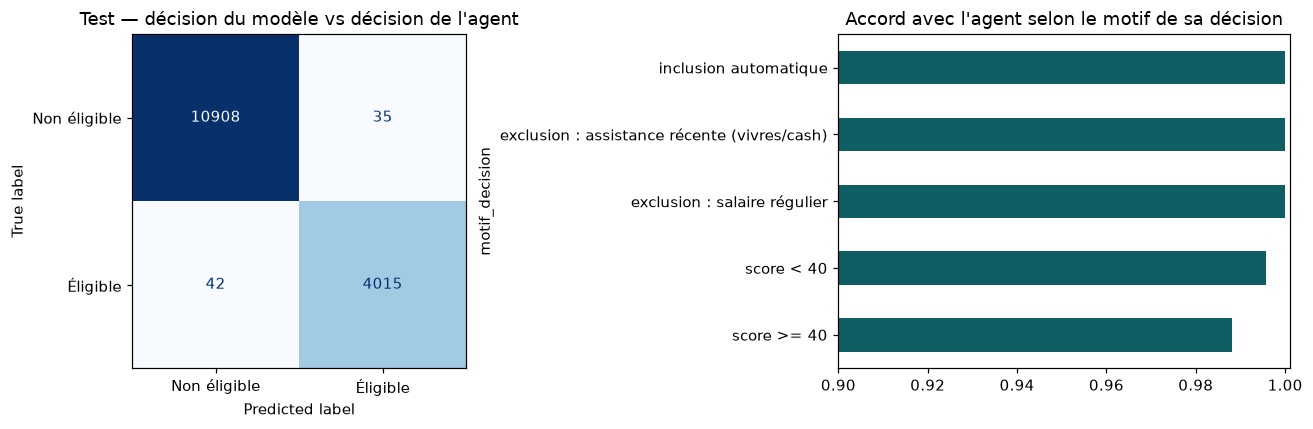

In [5]:
pv = p_va["Score prédit + LightGBM"]
grille_s = np.round(np.arange(0.05, 0.96, 0.01), 2)
prec_s = np.array([precision_score(y[i_va], pv >= t) for t in grille_s])
f1_s = np.array([f1_score(y[i_va], pv >= t) for t in grille_s])
SEUIL = float(grille_s[prec_s >= 0.98][np.argmax(f1_s[prec_s >= 0.98])])  # meilleur F1 parmi les seuils à précision >= 98 %

p_te = proba_stack(X_te)
pred_te = p_te >= SEUIL
res = {"précision": precision_score(y[i_te], pred_te), "rappel": recall_score(y[i_te], pred_te),
       "F1": f1_score(y[i_te], pred_te), "accuracy": accuracy_score(y[i_te], pred_te),
       "erreur moyenne du score prédit (points)": mean_absolute_error(score[i_te], modele_score.predict(X_te))}
print(f"Seuil retenu sur la validation : {SEUIL:.2f}")
display(pd.Series(res, name="TEST").to_frame().T.style.format("{:.4f}"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ConfusionMatrixDisplay(confusion_matrix(y[i_te], pred_te), display_labels=["Non éligible", "Éligible"]).plot(ax=axes[0], colorbar=False, cmap="Blues")
axes[0].set_title("Test — décision du modèle vs décision de l'agent")
motifs = df.iloc[i_te].assign(ok=(pred_te == y[i_te])).groupby("motif_decision").ok.mean().sort_values()
motifs.plot.barh(ax=axes[1], color="#0f5e63", xlim=(0.9, 1.001)); axes[1].set_title("Accord avec l'agent selon le motif de sa décision")
plt.tight_layout(); plt.show()

Le modèle reproduit aussi les **règles d'exception** : les exclusions et les inclusions automatiques sont presque toujours respectées. Les erreurs restantes concernent des ménages dont le score est **à un ou deux points du seuil**, là où l'erreur d'environ 0,3 point du score prédit peut faire basculer la décision. Sur le terrain, ces ménages passent dans la zone grise du dashboard pour être revus.

In [6]:
erreurs = df.iloc[i_te][pred_te != y[i_te]]
print(f"{len(erreurs)} désaccords sur {len(i_te):,} ménages — distance au seuil (points) :")
(erreurs.score_excel - gen.SEUIL_ELIGIBILITE).value_counts().sort_index().to_frame("ménages").T

77 désaccords sur 15,000 ménages — distance au seuil (points) :


score_excel,-2,-1,0,1
ménages,2,33,40,2


## 5. Explicabilité

LightGBM calcule nativement les **valeurs SHAP** (TreeSHAP). Pour la décision, l'information principale passe par le score prédit. On explique donc d'abord ce **score** question par question (en points), comme une ligne de la feuille Excel.

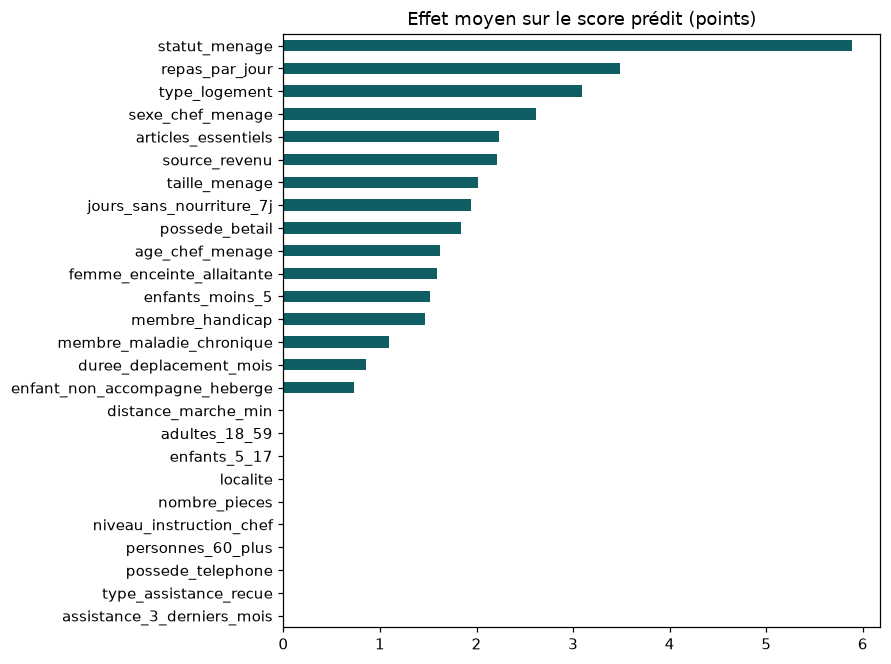

In [7]:
def contributions_score(Xp):
    pre, m = modele_score.named_steps["pre"], modele_score.named_steps["m"]
    noms = pre.get_feature_names_out()
    question = [next(c for c in X.columns if n.split("__", 1)[1].replace("missingindicator_", "") == c
                     or n.split("__", 1)[1].startswith(c + "_")) for n in noms]
    brut = m.predict(pre.transform(Xp), pred_contrib=True)
    return pd.DataFrame(brut[:, :-1], columns=question, index=Xp.index).T.groupby(level=0).sum().T, brut[:, -1]

contrib, base = contributions_score(X_te.iloc[:3000])
imp = contrib.abs().mean().sort_values()
imp.plot.barh(figsize=(7, 7), color=["#bbb" if v < 0.05 else "#0f5e63" for v in imp]); plt.title("Effet moyen sur le score prédit (points)"); plt.show()

Les questions qui ne figurent pas dans la grille (instruction du chef, téléphone, distance au marché, localité, nombre de pièces) n'ont **aucun effet** (en gris). Le modèle a retrouvé exactement les critères de l'ONG.

Score prédit : 39.6 points (feuille Excel : 39) | décision modèle : ÉLIGIBLE | agent : score < 40


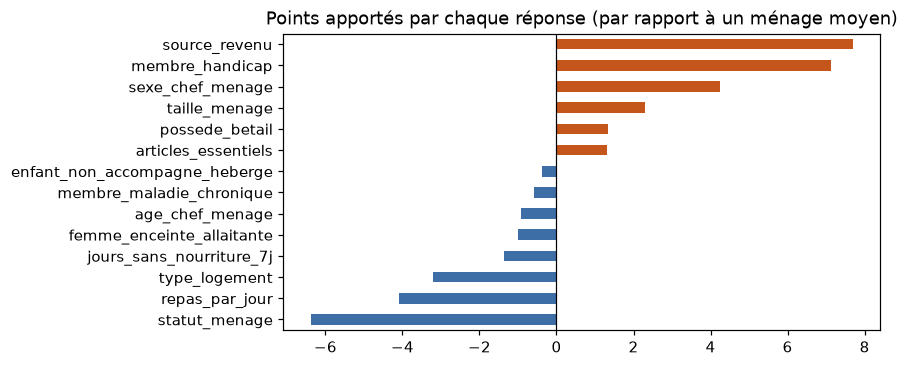

In [8]:
k = int(np.argmin(np.abs(p_te - 0.5)))  # le ménage le plus difficile du test
menage = X_te.iloc[[k]]
c, b = contributions_score(menage)
reel = df.iloc[i_te[k]]
print(f"Score prédit : {b[0] + c.iloc[0].sum():.1f} points (feuille Excel : {reel.score_excel}) | décision modèle : "
      f"{'ÉLIGIBLE' if p_te[k] >= SEUIL else 'NON ÉLIGIBLE'} | agent : {reel.motif_decision}")
c.iloc[0][c.iloc[0].abs() > 0.3].sort_values().plot.barh(color=["#c4551b" if v > 0 else "#3d6fa6" for v in c.iloc[0][c.iloc[0].abs() > 0.3].sort_values()], figsize=(7, 3.5))
plt.axvline(0, c="k", lw=.8); plt.title("Points apportés par chaque réponse (par rapport à un ménage moyen)"); plt.show()

## 6. Sélection sous contrainte budgétaire

**Scénario** : dans le jeu de test, le modèle déclare environ 5 400 ménages éligibles, et le budget ne permet d'en servir que **30 %** (l'équivalent de 3 000 sur 10 000).
Quel score ML reproduit le mieux la liste que l'agent aurait produite (score Excel décroissant, puis ménage le plus grand) ?

| Score de classement | Principe |
|---|---|
| Probabilité d'éligibilité | la certitude du classifieur |
| Log-odds de la régression logistique | la méthode du backend jusqu'ici |
| Log-odds de LightGBM | même idée, avec un meilleur classifieur |
| **Score Excel prédit** | le modèle de priorité appris sur les scores historiques |

In [9]:
dt = df.iloc[i_te].copy()
dt["eligible_modele"] = pred_te
rang_agent = gen.classement_excel(dt)                      # la liste de l'agent (sur ses propres éligibles)
pool = dt[dt.eligible_modele]                              # les éligibles selon le modèle
Xp = X.loc[pool.index]
logit = lambda q: np.log(np.clip(q, 1e-12, 1 - 1e-12) / (1 - np.clip(q, 1e-12, 1 - 1e-12)))
methodes = {
    "Probabilité d'éligibilité": lgbm.predict_proba(Xp)[:, 1],
    "Log-odds régression logistique": logit(lr.predict_proba(Xp)[:, 1]),
    "Log-odds LightGBM": lgbm.named_steps["m"].predict(lgbm.named_steps["pre"].transform(Xp), raw_score=True),
    "Score Excel prédit": modele_score.predict(Xp),
}

def selection(priorite, n):
    ordre = np.lexsort((-pool.taille_menage.to_numpy(), -np.round(priorite, 6)))  # même départage que l'agent
    return set(pool.index[ordre[:n]])

N = int(len(rang_agent) * 0.30)
liste_agent = set(rang_agent.index[:N])
tab = pd.DataFrame({nom: {"recouvrement avec la liste de l'agent": len(selection(s, N) & liste_agent) / N,
                          "corrélation de rang (Spearman)": spearmanr(s, pool.score_excel).correlation,
                          "ex aequo": pd.Series(np.round(s, 6)).duplicated().mean()} for nom, s in methodes.items()}).T
print(f"{len(rang_agent):,} éligibles selon l'agent, {len(pool):,} selon le modèle, budget N = {N:,}")
tab.style.format("{:.1%}", subset=["recouvrement avec la liste de l'agent", "ex aequo"]).format("{:.3f}", subset=["corrélation de rang (Spearman)"]).highlight_max(color="#e0f1e6")

4,057 éligibles selon l'agent, 4,050 selon le modèle, budget N = 1,217


,recouvrement avec la liste de l'agent,corrélation de rang (Spearman),ex aequo
Probabilité d'éligibilité,84.6%,0.902,50.1%
Log-odds régression logistique,82.6%,0.857,0.0%
Log-odds LightGBM,84.6%,0.902,0.0%
Score Excel prédit,96.1%,0.996,0.0%


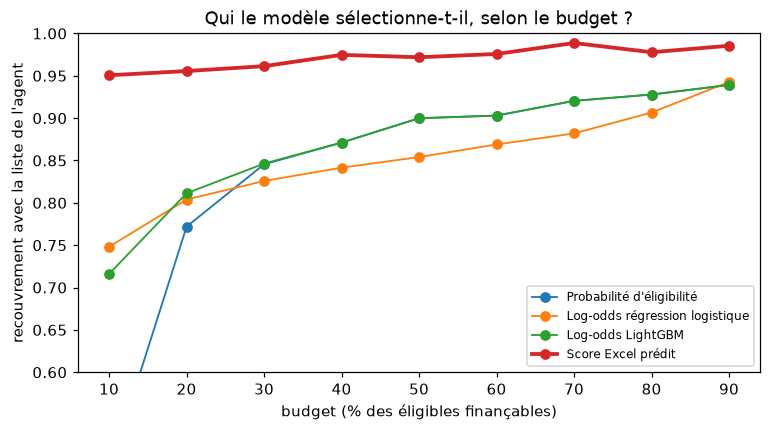

In [10]:
parts = np.arange(0.1, 0.91, 0.1)
fig, ax = plt.subplots(figsize=(8, 4))
for nom, s in methodes.items():
    rec = [len(selection(s, int(len(rang_agent) * q)) & set(rang_agent.index[:int(len(rang_agent) * q)])) / int(len(rang_agent) * q) for q in parts]
    ax.plot(parts * 100, rec, marker="o", label=nom, lw=2.5 if nom == "Score Excel prédit" else 1.2)
ax.set_xlabel("budget (% des éligibles finançables)"); ax.set_ylabel("recouvrement avec la liste de l'agent")
ax.set_ylim(0.6, 1.0); ax.legend(fontsize=8); ax.set_title("Qui le modèle sélectionne-t-il, selon le budget ?"); plt.show()

- **La probabilité d'éligibilité ne sert pas à prioriser.** Elle mesure la *certitude* du modèle, pas l'intensité des besoins. La moitié des ménages sont à égalité à 1,00, et un ménage à 80 points n'est pas « plus certain » qu'un ménage à 50.
- **Les log-odds d'un classifieur** départagent mieux, mais restent une mesure de certitude : environ 15 % de la liste diffère de celle de l'agent.
- **Le score Excel prédit** retrouve **96 % de la liste de l'agent**, et reste au-dessus de 95 % quel que soit le budget. L'écart est le plus grand quand le budget est petit : à 10 % des éligibles, classer par probabilité retrouve moins de 60 % de la liste de l'agent. Apprendre directement le *score* historique donne bien plus d'information qu'apprendre seulement « éligible oui ou non ».

**Conséquence pour le backend** : quand l'historique contient le score de l'agent (c'est le cas du jeu v3, avec `Score_Vuln`), il faut entraîner un **modèle de priorité** sur ce score et classer avec lui. Les log-odds ne servent plus que de solution de repli. Cette modification est faite dans `training/train.py` et `app/ml.py`.

In [11]:
s_pred = methodes["Score Excel prédit"]
liste_globale = selection(s_pred, N)
eff = pool.localite.value_counts().to_dict()
quotas = repartir(N, eff)
liste_zone = set()
for zone, q in quotas.items():
    z = pool[pool.localite == zone]
    ordre = np.lexsort((-z.taille_menage.to_numpy(), -np.round(s_pred[pool.localite.to_numpy() == zone], 6)))
    liste_zone |= set(z.index[ordre[:q]])
couverture = pd.DataFrame({
    "éligibles": pd.Series(eff),
    "retenus — global": pool.loc[list(liste_globale)].localite.value_counts(),
    "retenus — par zone": pool.loc[list(liste_zone)].localite.value_counts(),
}).fillna(0).astype(int)
couverture["couverture globale"] = couverture["retenus — global"] / couverture["éligibles"]
couverture["couverture par zone"] = couverture["retenus — par zone"] / couverture["éligibles"]
couverture.style.format("{:.1%}", subset=["couverture globale", "couverture par zone"])

,éligibles,retenus — global,retenus — par zone,couverture globale,couverture par zone
Birambizo,936,337,281,36.0%,30.0%
Kibirizi,830,271,249,32.7%,30.0%
Bambo,693,195,208,28.1%,30.0%
Binza,648,185,195,28.5%,30.1%
Rwanguba,509,129,153,25.3%,30.1%
Rutshuru,434,100,131,23.0%,30.2%


- **En mode global**, les zones les plus touchées (Birambizo, Kibirizi) reçoivent une part plus que proportionnelle : le budget suit l'intensité des besoins.
- **En mode par zone**, la couverture est presque identique partout (environ 30 %) : on garantit l'équité géographique, au prix de servir des ménages moins vulnérables dans les zones moins touchées.

C'est un **choix de programme**, que le backend laisse au superviseur (page *Sélection*).

## 7. Robustesse : validation temporelle

In [12]:
dates = pd.to_datetime(df.date_enquete)
avant, apres = (dates < "2026-07-01").to_numpy(), (dates >= "2026-07-01").to_numpy()
ms = regresseur_score().fit(X[avant], score[avant])
oof_t = cross_val_predict(regresseur_score(), X[avant], score[avant], cv=KFold(5, shuffle=True, random_state=SEED))
cl = classifieur(NUM + ["score_predit"]).fit(avec_score(X[avant], oof_t), y[avant])
p_t = cl.predict_proba(avec_score(X[apres], ms.predict(X[apres])))[:, 1] >= SEUIL
print(f"Train janvier–juin ({avant.sum():,} ménages), test juillet–août ({apres.sum():,}) : "
      f"précision {precision_score(y[apres], p_t):.4f} | rappel {recall_score(y[apres], p_t):.4f} | "
      f"erreur du score prédit {mean_absolute_error(score[apres], ms.predict(X[apres])):.2f} point")

Train janvier–juin (73,924 ménages), test juillet–août (26,076) : précision 0.9889 | rappel 0.9931 | erreur du score prédit 0.34 point


## Conclusion

| | Résultat (test) |
|---|---|
| Décision éligible / non éligible (score prédit + LightGBM) | **précision 99,1 %, rappel 99,0 %** ; les 77 désaccords sont tous à 2 points ou moins du seuil |
| Score de l'agent prédit | erreur moyenne d'environ 0,3 point |
| Liste sous budget (30 % des éligibles) | **96 %** de recouvrement avec la liste de l'agent, contre 83 à 85 % en classant par probabilité ou log-odds |

**Ce que ça change pour le backend**
1. `training/train.py` entraîne désormais **deux modèles** : la décision (éligible ou non) et la **priorité** (le score historique de l'agent, ici `Score_Vuln` pour le jeu v3).
2. La page **Sélection** classe les éligibles avec le **score prédit**, exprimé en points comme dans la feuille Excel. S'il n'y a pas de score historique, elle utilise les log-odds en repli.
   Sur le jeu v3 actuellement déployé, le gain est faible (97,1 % contre 96,9 %), car sa règle est une simple somme de points que la régression logistique représente déjà bien. Le gain devient important dès que la règle de l'ONG contient des exclusions ou des inclusions automatiques, comme ici.
3. Les superviseurs gardent la main : ils confirment ou désapprouvent les décisions, choisissent le mode de répartition et voient les ménages juste sous la ligne de coupure.

**Sur données réelles**, les décisions des agents contiennent du jugement : la précision sera plus basse et la revue humaine du dashboard devient essentielle. Les désaccords enregistrés servent à ré-entraîner les modèles.